<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-06/ising-cvae.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Ising configurations from a conditional VAE

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

For the two-dimensional (2D) Ising model the distribution of spin configurations is known exactly. A configuration $\mathbf s$, the list of $N$ spins $s_1,\dots,s_N$, each taking the value $+1$ or $-1$, occurs at temperature $T$ with the Boltzmann probability
$$
p(\mathbf s\,|\,T)=\frac{e^{-H(\mathbf s)/T}}{Z(T)}, \tag{1}
$$
with the energy
$$
H(\mathbf s)=-\sum_{\langle ij\rangle}s_is_j , \tag{2}
$$
where the sum runs over all pairs $\langle ij\rangle$ of nearest neighbours on an $L\times L$ lattice with periodic boundaries ($N$ is $L^2$), the coupling and the Boltzmann constant are set to 1, and $Z(T)$ normalises the distribution. Metropolis Monte Carlo (MC) sampling [[2]](#references) draws configurations from equation (1), and Onsager's exact solution [[1]](#references) gives the critical temperature of the infinite lattice,
$$
T_c=\frac{2}{\ln\left(1+\sqrt2\right)}\approx 2.269 . \tag{3}
$$
The Ising model is therefore a demanding test of a generative model: its samples can be checked not only by eye but with the observables of statistical physics, and with other neural networks.

In Lecture 6 a conditional variational autoencoder (cVAE; the VAE was introduced in [[5]](#references)) was trained on MC configurations with the temperature as the condition, and the magnetisation and energy of its samples were compared with MC. The same model, retrained with the same seed, is tested further on its generated configurations:

- thermodynamic observables at every temperature: the mean absolute magnetisation, the energy per spin and their fluctuations;
- the spin–spin correlation function at several distances;
- the critical temperature found by a phase classifier from its confidence (the method of Lab 011), with the classifier trained on MC data or on generated data;
- a convolutional network that reads the temperature off a configuration, again trained on MC or on generated data.

All computations run on the central processing unit (CPU), and all random generators are seeded.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""          # CPU only
import json, time, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
try:
    from torchinfo import summary
except ImportError:                              # e.g. in Google Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo"], check=True)
    from torchinfo import summary
torch.set_num_threads(4)
t_start = time.time()

import os
OUT = "figures"; os.makedirs(OUT, exist_ok=True); os.makedirs(OUT, exist_ok=True)       # figures used on the slides
RES = "results"; os.makedirs(RES, exist_ok=True)                 # weights and numbers
blue, orange, navy, gray = "#005CA7", "#EB6709", "#0A2F5C", "#5A6270"
TC = 2 / np.log(1 + np.sqrt(2))                                  # Onsager's critical temperature, J = k_B = 1
nums = {}                                                        # numbers quoted on the slides
def clean(ax):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
def seed(k):
    torch.manual_seed(k); return np.random.default_rng(k)
def slide_style():
    # large fonts for figures shown at about 0.9 of the width of a 16:9 slide
    plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13,
                         "legend.fontsize": 13, "figure.titlesize": 17, "figure.facecolor": "white", "savefig.facecolor": "white"})
slide_style()
print("PyTorch", torch.__version__, "| threads", torch.get_num_threads(), f"| Onsager T_c = {TC:.4f}")

PyTorch 2.9.0+cpu | threads 4 | Onsager T_c = 2.2692


## Monte Carlo data

One sample is a configuration of the $20\times20$ lattice: an array of 400 numbers $s_i$, one per site, with $+1$ for a spin pointing up and $-1$ for a spin pointing down. The lattice has periodic boundaries, so it is a torus: the right neighbour of a site in the last column is the site in the first column of the same row, and likewise for rows. Each configuration carries one label, the temperature $T$ of the MC run that produced it.

The configurations are those of Lecture 4, sampled by the Metropolis algorithm [[2]](#references). A proposed flip of spin $i$ changes the energy of equation (2) by
$$
\Delta E_i=2\,s_i\sum_{j\in\mathrm{nn}(i)}s_j , \tag{4}
$$
where $\mathrm{nn}(i)$ are the four nearest neighbours of site $i$, and the flip is accepted with probability
$$
A_i=\min\left(1,\,e^{-\Delta E_i/T}\right). \tag{5}
$$
This rule obeys detailed balance with respect to equation (1), so after many updates the chain visits configurations with the Boltzmann probability. In the checkerboard version all sites of one colour of a chessboard pattern are updated at once, since their neighbours all have the other colour; one sweep, one attempted flip per spin, consists of two such half-updates.

For each of the 51 temperatures 1.00, 1.05, …, 3.50, 20 independent chains start from the fully ordered state and run 1000 sweeps of equilibration, long enough to forget the starting point. Each chain then stores one configuration every 20 sweeps, ten times. The gap reduces the correlation between consecutive stored configurations, although near $T_c$, where the Metropolis dynamics slows down, consecutive configurations of a chain remain partly correlated. This gives 200 configurations per temperature and 10 200 in total. Each stored configuration is finally multiplied by a random global sign: the energy of equation (2) does not change when all spins are flipped, but a cold start would otherwise leave every low-temperature configuration with positive magnetisation.

Where the file of Lecture 4 is not available, as in Google Colab, a local copy in `data/` is used, or else the data set is regenerated with the same sampler in about a minute.

In [2]:
def metropolis_sweep(s, beta, masks, rng):
    # one checkerboard Metropolis sweep (in place) of a batch of lattices s: (..., L, L), periodic boundaries
    for mask in masks:
        nn_sum = np.roll(s, 1, -1) + np.roll(s, -1, -1) + np.roll(s, 1, -2) + np.roll(s, -1, -2)
        accept = rng.random(s.shape, dtype=np.float32) < np.exp(-beta * 2.0 * s * nn_sum)
        s[...] = np.where(mask & accept, -s, s)

def generate_dataset(L, temperatures, n_chains=20, n_samples=10, n_equil=1000, n_between=20, rng=None):
    y, x = np.indices((L, L)); black = (x + y) % 2 == 0
    beta = (1.0 / temperatures.astype(np.float32))[None, :, None, None]
    s = np.ones((n_chains, len(temperatures), L, L), np.float32)            # cold start
    for _ in range(n_equil): metropolis_sweep(s, beta, (black, ~black), rng)
    stored = np.empty((n_samples, n_chains, len(temperatures), L, L), np.int8)
    for k in range(n_samples):
        for _ in range(n_between): metropolis_sweep(s, beta, (black, ~black), rng)
        stored[k] = s
    configs = stored.transpose(2, 0, 1, 3, 4).reshape(len(temperatures), n_samples * n_chains, L, L)
    flip = rng.choice(np.array([-1, 1], np.int8), size=configs.shape[:2])   # random global spin flip
    return configs * flip[:, :, None, None]

candidates = ["data/ising_Nx20_Ny20.npz", "data/ising_Nx20_Ny20.npz"]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    t0 = time.time(); Ts_new = np.round(np.arange(1.0, 3.5 + 1e-9, 0.05), 2)
    configs_new = generate_dataset(20, Ts_new, rng=np.random.default_rng(0))
    os.makedirs("data", exist_ok=True); path = candidates[1]
    np.savez_compressed(path, configs=configs_new, T=Ts_new, Nx=20, Ny=20)
    print(f"regenerated the data set in {time.time() - t0:.0f} s")
d = np.load(path); cfg, Ts = d["configs"].astype(np.float32), d["T"]
nT, nS, L = cfg.shape[0], cfg.shape[1], cfg.shape[-1]; N = L * L
print("file:", path)
print("Monte Carlo configurations:", cfg.shape, "| temperatures", Ts[0], "...", Ts[-1], "in steps of", round(Ts[1] - Ts[0], 2))
print("fraction of configurations with positive magnetisation:", round(float((cfg.mean((-1, -2)) > 0).mean()), 3))
print("values in one configuration:", np.unique(cfg[0, 0]), "| first row of the first configuration at T =", Ts[0], ":", cfg[0, 0, 0].astype(int))

file: ../../Lecture_04_2026.10.14/Notebooks/data/ising_Nx20_Ny20.npz
Monte Carlo configurations: (51, 200, 20, 20) | temperatures 1.0 ... 3.5 in steps of 0.05
fraction of configurations with positive magnetisation: 0.498
values in one configuration: [1.] | first row of the first configuration at T = 1.0 : [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


The figure shows three configurations at each of six temperatures (white: spin up, black: spin down) and the mean absolute magnetisation $\langle|m|\rangle_T$, the average over the 200 configurations at temperature $T$ of the absolute value of the magnetisation per spin
$$
m=\frac1N\sum_{i=1}^N s_i . \tag{6}
$$
At temperature 1.5 nearly all spins are aligned, apart from a few isolated flipped spins, and both signs of the ordered state occur. Around $T_c$ domains of many sizes appear, and at 3.5 the spins are correlated only over a few lattice spacings. On a finite lattice $\langle|m|\rangle_T$ drops smoothly rather than sharply, and it stays above zero at high temperature because the magnetisation of $N$ nearly independent spins is of the order of one over the square root of $N$.

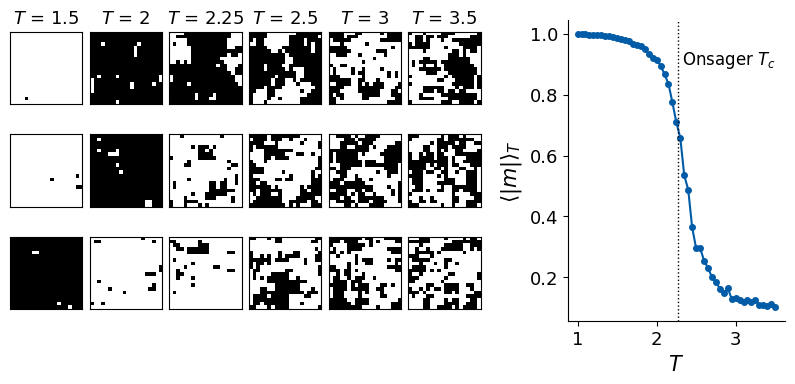

In [3]:
T_data = [1.5, 2.0, 2.25, 2.5, 3.0, 3.5]
fig = plt.figure(figsize=(10, 3.9))
gs = fig.add_gridspec(3, len(T_data) + 2, width_ratios=[1] * len(T_data) + [1.0, 3.0], wspace=0.08, hspace=0.08)
for k, T in enumerate(T_data):
    i = int(np.argmin(np.abs(Ts - T)))
    for j in range(3):
        a = fig.add_subplot(gs[j, k]); a.imshow(cfg[i, 5 * j], cmap="gray", vmin=-1, vmax=1, interpolation="nearest")
        a.set_xticks([]); a.set_yticks([])
        if j == 0: a.set_title(f"$T$ = {Ts[i]:g}", fontsize=13)
a = fig.add_subplot(gs[:, -1])
a.plot(Ts, np.abs(cfg.mean((-1, -2))).mean(1), "o-", ms=4, color=blue)
a.axvline(TC, color="k", ls=":", lw=1); a.text(TC + 0.05, 0.9, "Onsager $T_c$", fontsize=12)
a.set_xlabel("$T$"); a.set_ylabel(r"$\langle |m| \rangle_T$"); clean(a)
plt.savefig(f"{OUT}/ising_cvae_examples.png", dpi=200, bbox_inches="tight"); plt.show()

## The conditional VAE

The model is the cVAE of the Lecture 6 notebook, unchanged. Each spin becomes a pixel
$$
x_i=\frac{s_i+1}{2}\in\{0,1\}, \tag{7}
$$
so a configuration is a vector $\mathbf x$ of $D$ zeros and ones, with $D$ equal to 400. The condition is the rescaled temperature
$$
c=\frac{T-2.25}{0.75}, \tag{8}
$$
which runs from $-1.67$ to $1.67$ and is of the same order as the other inputs of the network.

The encoder receives $\mathbf x$ together with $c$ and passes them through fully connected layers of 256 and 128 rectified linear units (ReLU). Two linear output layers give the mean $\boldsymbol\mu$ and the logarithm of the variance $\log\boldsymbol\sigma^2$ of a Gaussian distribution over the 8 latent variables. During training a latent vector is drawn with the reparametrisation trick,
$$
\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon,\qquad \boldsymbol\varepsilon\sim\mathcal N(0,I), \tag{9}
$$
where $\odot$ is the element-wise product. The decoder receives $\mathbf z$ together with $c$ and passes them through layers of 128 and 256 units to 400 outputs $y_j$ between 0 and 1, the probability that spin $j$ points up. Given $\mathbf z$ and $c$, the decoder therefore describes a configuration by a product of independent Bernoulli distributions,
$$
p_\theta(\mathbf s\,|\,\mathbf z,c)=\prod_{j=1}^{400}y_j^{(1+s_j)/2}\,(1-y_j)^{(1-s_j)/2}, \tag{10}
$$
where $\theta$ denotes the weights of the decoder. The loss for one configuration is the binary cross-entropy (BCE) between $\mathbf x$ and $\mathbf y$ plus the Kullback–Leibler (KL) divergence between the encoder's Gaussian and the prior $\mathcal N(0,I)$,
$$
\mathcal L=-\sum_{j=1}^{400}\left[x_j\ln y_j+(1-x_j)\ln(1-y_j)\right]+\frac12\sum_{k=1}^{8}\left(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\right), \tag{11}
$$
averaged over the configurations of a mini-batch.

In [4]:
def mlp(sizes):
    # fully connected layers with ReLU in between (no activation after the last layer)
    layers = []
    for a, b in zip(sizes[:-1], sizes[1:]):
        layers += [nn.Linear(a, b), nn.ReLU()]
    return nn.Sequential(*layers[:-1])

class VAE(nn.Module):
    def __init__(self, D=784, d=2, cond=0, hidden=(512, 256)):
        super().__init__()
        self.d, self.cond = d, cond
        self.enc = mlp([D + cond, *hidden]); self.enc.append(nn.ReLU())
        self.mu, self.logvar = nn.Linear(hidden[-1], d), nn.Linear(hidden[-1], d)
        self.dec = mlp([d + cond, *hidden[::-1], D])                  # outputs logits; sigmoid gives probabilities
    def encode(self, x, c=None):
        h = self.enc(x if c is None else torch.cat([x, c], 1))
        return self.mu(h), self.logvar(h)
    def decode(self, z, c=None):
        return self.dec(z if c is None else torch.cat([z, c], 1))
    def forward(self, x, c=None):
        mu, logvar = self.encode(x, c)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)      # reparametrisation trick
        return self.decode(z, c), mu, logvar

def vae_loss(logits, x, mu, logvar):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
    kl = 0.5 * (mu ** 2 + logvar.exp() - logvar - 1).sum() / len(x)
    return rec + kl, rec, kl

def train_vae(model, X, C=None, epochs=20, lr=1e-3, bs=128):
    opt = torch.optim.Adam(model.parameters(), lr)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(X)); tot = np.zeros(3)
        for i in range(0, len(perm), bs):
            j = perm[i:i + bs]; x = X[j]; c = None if C is None else C[j]
            logits, mu, logvar = model(x, c)
            loss, rec, kl = vae_loss(logits, x, mu, logvar)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += np.array([loss.item(), rec.item(), kl.item()]) * len(j)
        hist.append(tot / len(X))
    return np.array(hist)

### Network architecture

`torchinfo` lists the layers of the encoder and of the decoder with the tensor shapes for one configuration and the numbers of trainable parameters. The layer sizes of the drawing are read from the same model. Every layer is a column of nodes; a layer with more than six units is drawn with its first and last three nodes around an ellipsis, and its true number of units is written under it. The lines are the trainable connections between consecutive layers, drawn between the visible nodes. The condition $T$ enters twice, as an extra input of the encoder and of the decoder. The dashed lines from $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$ to $\mathbf z$ are not weights but the sampling step of equation (9).

In [5]:
class Encoder(nn.Module):                       # view of the encoder part of a VAE
    def __init__(self, vae):
        super().__init__(); self.enc, self.mu, self.logvar = vae.enc, vae.mu, vae.logvar
    def forward(self, x, c):
        h = self.enc(torch.cat([x, c], 1)); return self.mu(h), self.logvar(h)
class Decoder(nn.Module):                       # view of the decoder part of a VAE
    def __init__(self, vae):
        super().__init__(); self.dec = vae.dec
    def forward(self, z, c):
        return torch.sigmoid(self.dec(torch.cat([z, c], 1)))

ivae = VAE(D=N, d=8, cond=1, hidden=(256, 128))
cols = ("input_size", "output_size", "num_params")
s_enc = summary(Encoder(ivae), input_data=[torch.zeros(1, N), torch.zeros(1, 1)], col_names=cols, verbose=0)
s_dec = summary(Decoder(ivae), input_data=[torch.zeros(1, 8), torch.zeros(1, 1)], col_names=cols, verbose=0)
print(s_enc); print(s_dec)
n_params = sum(p.numel() for p in ivae.parameters())
assert n_params == s_enc.total_params + s_dec.total_params == 274976
print(f"trainable parameters of the cVAE: {n_params:,}")

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Encoder                                  [1, 400]                  [1, 8]                    --
├─Sequential: 1-1                        [1, 401]                  [1, 128]                  --
│    └─Linear: 2-1                       [1, 401]                  [1, 256]                  102,912
│    └─ReLU: 2-2                         [1, 256]                  [1, 256]                  --
│    └─Linear: 2-3                       [1, 256]                  [1, 128]                  32,896
│    └─ReLU: 2-4                         [1, 128]                  [1, 128]                  --
├─Linear: 1-2                            [1, 128]                  [1, 8]                    1,032
├─Linear: 1-3                            [1, 128]                  [1, 8]                    1,032
Total params: 137,872
Trainable params: 137,872
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.14
Inpu

encoder: 400 + 1 -> [256, 128] -> mu, log sigma^2: 8 | decoder: 8 + 1 -> [128, 256] -> 400


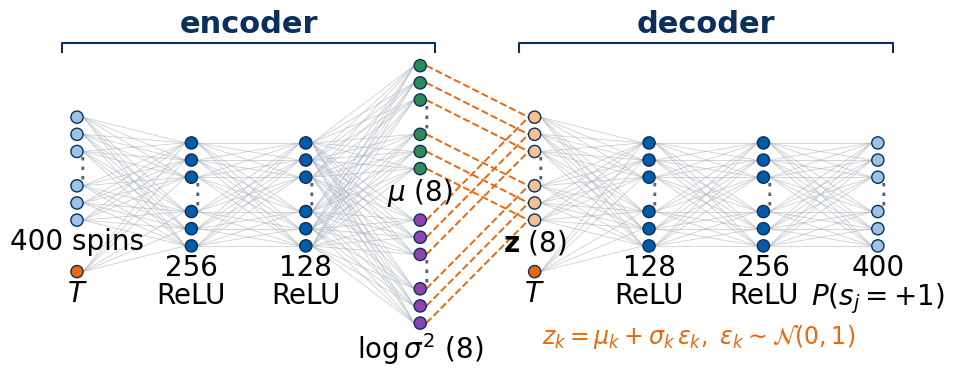

In [6]:
def draw_network(ax, columns, gaps, max_full=6, n_edge=3, dx=3.0, dy=0.45, r=0.16, fs=20,
                 edge_colour="#A9B0B8", groups=None):
    '''Draw a layered network as columns of nodes connected by edges.

    ax         : matplotlib axes to draw on
    columns    : list of columns from left to right; each column is a list of blocks, each block a dict with
                 size (number of units), colour (node fill colour), label (text written under the block) and
                 incoming (False for an input injected at this column, such as the condition, which gets no edges)
    gaps       : one entry per pair of consecutive columns: "dense" (every unit connected to every unit of the
                 next column, a fully connected layer) or "sample" (unit k of each block connected to unit k of
                 the next column, dashed: the sampling step z = mu + sigma * eps)
    max_full   : blocks with at most this many units are drawn completely
    n_edge     : larger blocks show their first n_edge and last n_edge units around an ellipsis
    dx, dy     : horizontal distance between columns and vertical distance between nodes (data units)
    r          : radius of a node (data units)
    fs         : font size of all labels, in points
    edge_colour: colour of the dense connections
    groups     : optional list of (first column, last column, text) brackets drawn above the network
    '''
    # node positions: each block is a vertical run of slots (a node or the ellipsis);
    # consecutive blocks of a column are separated by two empty slots, which leave room for the label
    pos, label_y = [], []                        # pos[c][b] = list of (x, y, unit index) of the visible nodes
    top = 0.0
    for c, col in enumerate(columns):
        slots = []                               # entries: (block, unit index), (block, "dots") or None
        for b, blk in enumerate(col):
            if b > 0: slots += [None, None]
            if blk["size"] <= max_full:
                slots += [(b, k) for k in range(blk["size"])]
            else:                                # truncation of a large layer
                slots += [(b, k) for k in range(n_edge)] + [(b, "dots")] + \
                         [(b, blk["size"] - n_edge + k) for k in range(n_edge)]
        ys = (np.arange(len(slots))[::-1] - (len(slots) - 1) / 2) * dy
        top = max(top, ys.max())
        x = c * dx
        pos.append([[] for _ in col])
        for sl, y in zip(slots, ys):
            if sl is None: continue
            b, k = sl
            if k == "dots":
                ax.text(x, y, r"$\vdots$", ha="center", va="center", fontsize=fs, color=gray)
            else:
                pos[c][b].append((x, y, k))
        # label under each block: the true number of units (and the layer type)
        for b, blk in enumerate(col):
            y_low = min(p[1] for p in pos[c][b]) - r - 0.05
            ax.text(x, y_low, blk["label"], ha="center", va="top", fontsize=fs, linespacing=1.0)
    # edges between consecutive columns
    for c, kind in enumerate(gaps):
        for b2, blk2 in enumerate(columns[c + 1]):
            if not blk2.get("incoming", True): continue
            for b1 in range(len(columns[c])):
                for (x1, y1, k1) in pos[c][b1]:
                    for (x2, y2, k2) in pos[c + 1][b2]:
                        if kind == "dense":
                            ax.plot([x1 + r, x2 - r], [y1, y2], color=edge_colour, lw=0.6, alpha=0.6, zorder=1)
                        elif kind == "sample" and k1 == k2:
                            ax.plot([x1 + r, x2 - r], [y1, y2], color=orange, lw=1.4, ls="--", zorder=1)
    # nodes, drawn last so that they cover the ends of the edges
    for c, col in enumerate(columns):
        for b, blk in enumerate(col):
            for (x, y, k) in pos[c][b]:
                ax.add_patch(plt.Circle((x, y), r, facecolor=blk["colour"], edgecolor=navy, lw=1.0, zorder=3))
    # encoder / decoder brackets above the network
    for (c1, c2, text) in (groups or []):
        yb = top + 0.6
        ax.plot([c1 * dx - 0.4, c1 * dx - 0.4, c2 * dx + 0.4, c2 * dx + 0.4], [yb - 0.25, yb, yb, yb - 0.25], color=navy, lw=1.5)
        ax.text((c1 + c2) * dx / 2, yb + 0.1, text, ha="center", va="bottom", fontsize=fs + 2, color=navy, weight="bold")
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_xlim(-1.3, (len(columns) - 1) * dx + 1.3)

# layer sizes read from the model
lin_enc = [m for m in ivae.enc if isinstance(m, nn.Linear)]
lin_dec = [m for m in ivae.dec if isinstance(m, nn.Linear)]
D_in, n_cond, d_lat = lin_enc[0].in_features - ivae.cond, ivae.cond, ivae.mu.out_features
h_enc, h_dec, D_out = [m.out_features for m in lin_enc], [m.out_features for m in lin_dec[:-1]], lin_dec[-1].out_features
print("encoder:", D_in, "+", n_cond, "->", h_enc, "-> mu, log sigma^2:", d_lat, "| decoder:", d_lat, "+", n_cond, "->", h_dec, "->", D_out)

# colours of the node types
c_in, c_T, c_h, c_mu, c_lv, c_z = "#9CC3E6", orange, blue, "#2E8B57", "#8E44AD", "#F6C08F"
columns = ([[dict(size=D_in, colour=c_in, label=f"{D_in} spins"), dict(size=n_cond, colour=c_T, label="$T$")]]
           + [[dict(size=h, colour=c_h, label=f"{h}\nReLU")] for h in h_enc]
           + [[dict(size=d_lat, colour=c_mu, label=rf"$\mu$ ({d_lat})"), dict(size=d_lat, colour=c_lv, label=rf"$\log\sigma^2$ ({d_lat})")]]
           + [[dict(size=d_lat, colour=c_z, label=rf"$\mathbf{{z}}$ ({d_lat})"), dict(size=n_cond, colour=c_T, label="$T$", incoming=False)]]
           + [[dict(size=h, colour=c_h, label=f"{h}\nReLU")] for h in h_dec]
           + [[dict(size=D_out, colour=c_in, label=f"{D_out}\n$P(s_j=+1)$")]])
gaps = ["dense"] * (len(h_enc) + 1) + ["sample"] + ["dense"] * (len(h_dec) + 1)
n_enc = len(h_enc) + 1                                              # index of the (mu, log sigma^2) column
fig = plt.figure(figsize=(9, 6.5)); ax = fig.add_axes([0, 0, 1, 1])        # axes fill the figure: 9 in of drawing
draw_network(ax, columns, gaps, groups=[(0, n_enc, "encoder"), (n_enc + 1, len(columns) - 1, "decoder")])
ax.text(16.3, -3.35, r"$z_k=\mu_k+\sigma_k\,\varepsilon_k,\ \varepsilon_k\sim\mathcal{N}(0,1)$",
        ha="center", va="top", fontsize=17, color=orange)
plt.savefig(f"{OUT}/ising_cvae_arch.png", dpi=200, bbox_inches="tight"); plt.show()

### Training

The model is trained for 60 epochs with the Adam optimiser (learning rate $10^{-3}$, mini-batches of 128 configurations) on all 10 200 MC configurations, with the same seed as in the Lecture 6 notebook.

training time 31 s
loss per configuration after 60 epochs: 139.2 = reconstruction 132.8 + KL 6.3


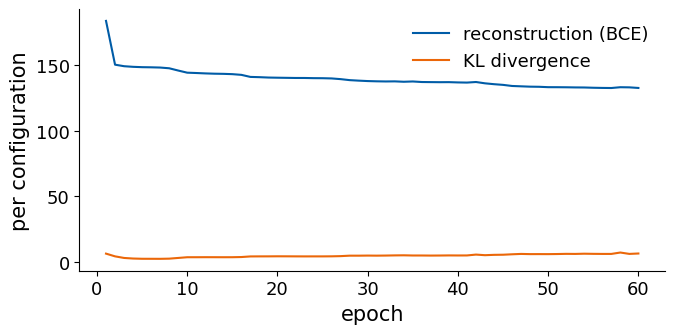

In [7]:
Xs = torch.tensor(((cfg + 1) / 2).reshape(-1, N))                      # spins -> pixels 0/1
Tn = lambda T: (np.asarray(T, np.float32) - 2.25) / 0.75              # the condition c
Cs = torch.tensor(np.repeat(Tn(Ts), nS))[:, None]

rng = seed(6)
ivae = VAE(D=N, d=8, cond=1, hidden=(256, 128))
t0 = time.time(); hist = train_vae(ivae, Xs, Cs, epochs=60); ivae.eval()
t_vae = time.time() - t0
torch.save(ivae.state_dict(), f"{RES}/ising_cvae.pt")
print(f"training time {t_vae:.0f} s")
print(f"loss per configuration after 60 epochs: {hist[-1, 0]:.1f} = reconstruction {hist[-1, 1]:.1f} + KL {hist[-1, 2]:.1f}")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, 61), hist[:, 1], color=blue, label="reconstruction (BCE)")
ax.plot(np.arange(1, 61), hist[:, 2], color=orange, label="KL divergence")
ax.set_xlabel("epoch"); ax.set_ylabel("per configuration"); ax.legend(frameon=False); clean(ax)
plt.tight_layout(); plt.show()

After 60 epochs the loss is 139.2 per configuration, of which 132.8 comes from the reconstruction and 6.3 from the KL divergence. Spread over 400 spins, the reconstruction cost is 0.33 nats per spin, about half of the cost of a fair coin for every spin, 0.69 nats (the natural logarithm of 2). The KL term measures how much information the encoder stores in the latent vector: 6.3 nats, about 9 bits, per configuration. This is enough for a coarse description of a configuration, such as the sign of its magnetisation and a rough outline of its largest domains; everything finer is left to the independent draws of equation (10).

## Generation at a chosen temperature

Generation does not use the encoder. For a chosen temperature $T$ we fix the condition of equation (8), draw a latent vector $\mathbf z$ from $\mathcal N(0,I)$, let the decoder compute the 400 probabilities $y_j$, and draw each spin independently from equation (10): up with probability $y_j$, down otherwise. Repeating this 200 times at each of the 51 training temperatures gives a generated data set of the same size and shape as the MC one. The figure shows two MC and two generated configurations at each of four temperatures.

generated (51, 200, 20, 20) in 0.11 s


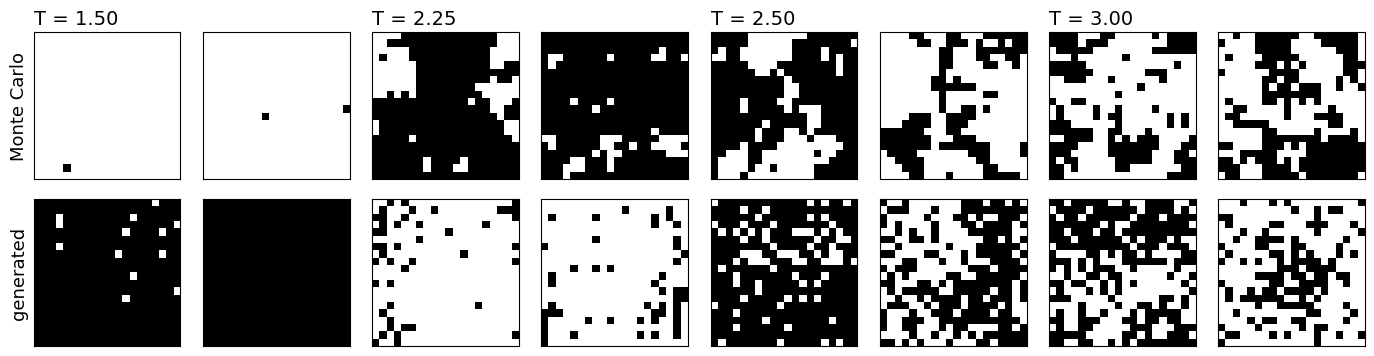

In [8]:
gen_rng = torch.Generator().manual_seed(12)
t0 = time.time()
with torch.no_grad():
    z = torch.randn(nT * nS, 8, generator=gen_rng)
    prob = torch.sigmoid(ivae.decode(z, Cs))                           # y_j = P(s_j = +1 | z, T)
    gen = (torch.bernoulli(prob, generator=gen_rng) * 2 - 1).numpy().reshape(nT, nS, L, L)
prob = prob.numpy().reshape(nT, nS, L, L)
print(f"generated {gen.shape} in {time.time() - t0:.2f} s")

T_show = [1.5, 2.25, 2.5, 3.0]
iT = lambda T: int(np.argmin(np.abs(Ts - T)))
fig, axs = plt.subplots(2, 2 * len(T_show), figsize=(14, 3.9))
for k, T in enumerate(T_show):
    for j in range(2):
        for r_, src in enumerate([cfg, gen]):
            a = axs[r_, 2 * k + j]
            a.imshow(src[iT(T), j], cmap="gray", vmin=-1, vmax=1, interpolation="nearest"); a.set_xticks([]); a.set_yticks([])
    axs[0, 2 * k].set_title(f"T = {Ts[iT(T)]:.2f}", loc="left", fontsize=14)
axs[0, 0].set_ylabel("Monte Carlo", fontsize=13); axs[1, 0].set_ylabel("generated", fontsize=13)
plt.tight_layout(); plt.show()

At temperature 1.5 the generated configurations are ordered, as in MC, but carry more scattered single flipped spins. At 2.25, where MC shows large compact domains, the generated configurations are nearly uniform with isolated flipped spins. At 2.5 and 3.0 they resemble salt-and-pepper noise on a weak large-scale pattern, without the compact clusters of MC. An isolated flipped spin breaks four bonds, so many of them raise the energy, and the observables quantify this.

## Observables

Besides the magnetisation of equation (6), we compute for every configuration the energy per spin,
$$
e=\frac{H(\mathbf s)}{N}=-\frac1N\sum_{i=1}^N s_i\left(s_{i+\hat x}+s_{i+\hat y}\right), \tag{12}
$$
where $i+\hat x$ and $i+\hat y$ are the right and the lower neighbour of site $i$ (periodic boundaries), so that every bond is counted once. Averages $\langle\cdot\rangle_T$ run over the 200 configurations at temperature $T$. Fluctuations are a sharper test than averages, since a model can place the mean correctly and still produce too narrow or too broad distributions. We therefore also compare the fluctuation of $|m|$, a finite-lattice analogue of the magnetic susceptibility,
$$
\chi'=\frac{N\,\mathrm{Var}_T(|m|)}{T}, \tag{13}
$$
and the energy fluctuation, which equals the heat capacity per spin,
$$
C'=\frac{N\,\mathrm{Var}_T(e)}{T^2}, \tag{14}
$$
where $\mathrm{Var}_T$ is the variance over the configurations at temperature $T$. On a finite lattice $\chi'$ and $C'$ have a maximum near, but not exactly at, $T_c$; the temperature of the maximum is a pseudo-critical temperature of the lattice. The fluctuations are plotted on a logarithmic scale.

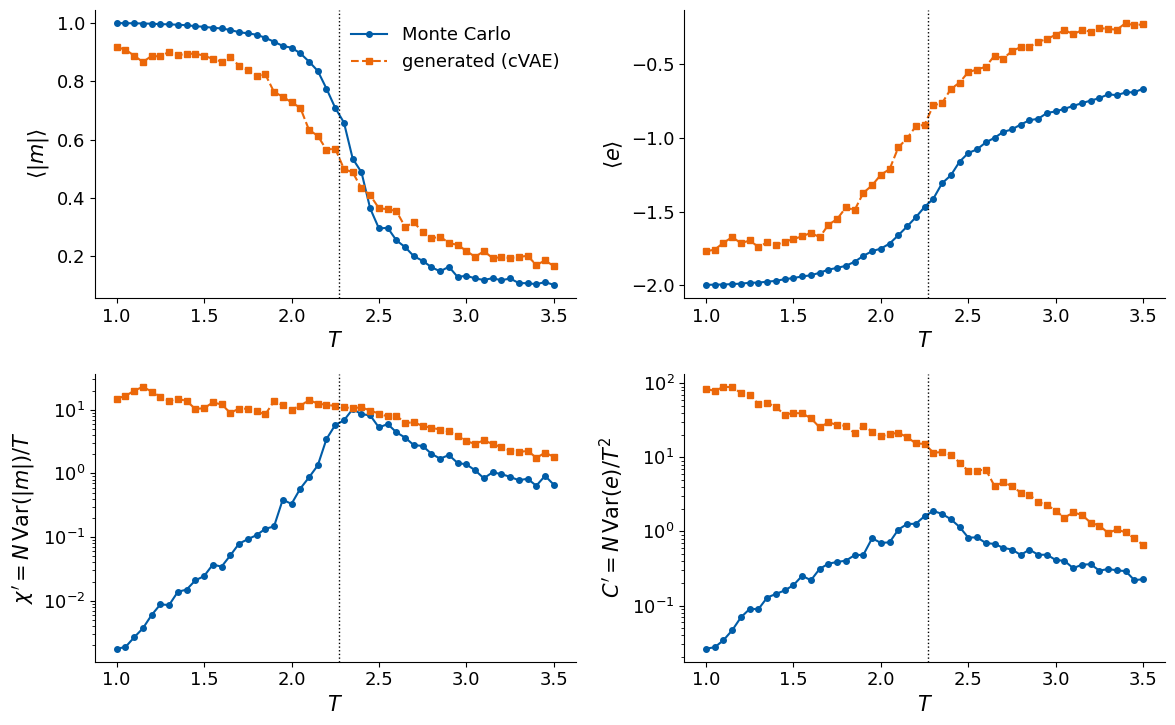

observable      largest |MC - generated|   at T     mean |MC - generated|   T of maximum (MC / generated)
M                  0.234               2.10           0.109             
E                  0.634               2.30           0.434             
chi               22.868               1.15           7.522             2.35 / 1.15
C                 89.456               1.10          22.609             2.30 / 1.10
temperatures up to 1.5: fraction of configurations with |m| below 0.5: MC 0.000, generated 0.085
                        median |m|: MC 0.995, generated 0.990


In [9]:
def energy(s):       # energy per spin, J = 1, periodic boundaries; s: (..., L, L) with values +-1
    return -(s * (np.roll(s, 1, -1) + np.roll(s, 1, -2))).mean((-1, -2))

def observables(s):
    m, e = np.abs(s.mean((-1, -2))), energy(s)                        # (temperatures, configurations)
    return dict(M=m.mean(1), E=e.mean(1), chi=N * m.var(1) / Ts, C=N * e.var(1) / Ts ** 2)
obs_mc, obs_gen = observables(cfg), observables(gen)

names = dict(M=r"$\langle |m| \rangle$", E=r"$\langle e \rangle$", chi=r"$\chi' = N\,\mathrm{Var}(|m|)/T$", C=r"$C' = N\,\mathrm{Var}(e)/T^2$")
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
for a, k in zip(axs.ravel(), names):
    if k in ("chi", "C"): a.set_yscale("log")                       # fluctuations span several decades
    a.plot(Ts, obs_mc[k], "o-", ms=4, color=blue, label="Monte Carlo")
    a.plot(Ts, obs_gen[k], "s--", ms=4, color=orange, label="generated (cVAE)")
    a.axvline(TC, color="k", ls=":", lw=1); a.set_xlabel("$T$"); a.set_ylabel(names[k]); clean(a)
axs[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

print("observable      largest |MC - generated|   at T     mean |MC - generated|   T of maximum (MC / generated)")
for k in names:
    diff = np.abs(obs_mc[k] - obs_gen[k]); i = int(np.argmax(diff))
    nums[f"gap_{k}"], nums[f"gap_{k}_T"], nums[f"meangap_{k}"] = float(diff[i]), float(Ts[i]), float(diff.mean())
    peak = f"{Ts[np.argmax(obs_mc[k])]:.2f} / {Ts[np.argmax(obs_gen[k])]:.2f}" if k in ("chi", "C") else ""
    if k in ("chi", "C"):
        nums[f"peak_{k}_mc"], nums[f"peak_{k}_gen"] = float(Ts[np.argmax(obs_mc[k])]), float(Ts[np.argmax(obs_gen[k])])
        nums[f"max_{k}_mc"], nums[f"max_{k}_gen"] = float(obs_mc[k].max()), float(obs_gen[k].max())
    print(f"{k:4s}            {diff[i]:8.3f}               {Ts[i]:.2f}        {diff.mean():8.3f}             {peak}")

low = Ts <= 1.5                                                   # the ordered phase, well below T_c
m_mc, m_gen = np.abs(cfg[low].mean((-1, -2))), np.abs(gen[low].mean((-1, -2)))
nums["frac_low_m_mc"], nums["frac_low_m_gen"] = float((m_mc < 0.5).mean()), float((m_gen < 0.5).mean())
print(f"temperatures up to 1.5: fraction of configurations with |m| below 0.5: MC {nums['frac_low_m_mc']:.3f}, generated {nums['frac_low_m_gen']:.3f}")
print(f"                        median |m|: MC {np.median(m_mc):.3f}, generated {np.median(m_gen):.3f}")

The magnetisation of the generated configurations follows the MC curve in shape and drops around $T_c$, but it is too low in the ordered phase and too high in the disordered one: the largest deviation is 0.234, at temperature 2.10, and the mean deviation over the 51 temperatures is 0.109. The energy per spin is too high at every temperature, by 0.434 on average and by up to 0.634 at temperature 2.30, close to $T_c$. These are the numbers quoted on the Lecture 6 slides (0.23 and 0.63 at 2.3), reproduced by the retrained model.

The fluctuations fail most clearly. In the MC data $\chi'$ and $C'$ have their maxima at temperatures 2.35 and 2.30, the pseudo-critical temperatures of the $20\times20$ lattice, with maximal values 10.2 and 1.89. For the generated configurations both quantities grow towards low temperature instead, up to 22.9 at temperature 1.15 and 89.5 at 1.10, where the MC fluctuations are two to three orders of magnitude smaller. The cause is a minority of wrong configurations. At temperatures up to 1.5, 8.5% of the generated configurations have $|m|$ below 0.5, against none of the MC configurations, while the median of $|m|$ is 0.99 for both. A variance is dominated by such rare outliers, whereas the average hides them. A plausible origin, not tested here, is the latent space: the two signs of the ordered state occupy two separate regions of $\mathbf z$, and latent vectors drawn from the Gaussian prior between these regions decode to mixed probability maps.

## Spin–spin correlation function

The energy of equation (12) measures correlations between nearest neighbours only. The correlation function extends this to larger distances. For a configuration $\mathbf s$ and a distance $r$ (in lattice units) we average the product of spins $r$ sites apart along $x$ and along $y$,
$$
g_{\mathbf s}(r)=\frac1{2N}\sum_{i=1}^N s_i\left(s_{i+r\hat x}+s_{i+r\hat y}\right), \tag{15}
$$
with periodic boundaries, and average over the configurations at temperature $T$,
$$
G(r)=\left\langle g_{\mathbf s}(r)\right\rangle_T . \tag{16}
$$
At distance 1, equations (12) and (16) are related by
$$
G(1)=-\tfrac12\,\langle e\rangle_T . \tag{17}
$$
Equation (16) is the full, not the connected, correlation function. Because of the random global sign the average of a single spin vanishes, and below $T_c$ the function $G(r)$ does not decay to zero but levels off near $\langle m^2\rangle_T$, the squared spontaneous magnetisation of the finite lattice. The part that decays with distance is the connected correlation function
$$
G_c(r)=G(r)-\langle m^2\rangle_T . \tag{18}
$$
The plots show $G(r)$ for distances 1 to 10 (half the lattice size) at four temperatures, with dotted lines at $\langle m^2\rangle_T$.

For the generated configurations equation (10) adds a constraint. Given $\mathbf z$, spin $j$ has the mean
$$
\bar s_j=2y_j-1, \tag{19}
$$
and, because the spins are drawn independently, the expected product of two different spins is
$$
\mathbb E\left[s_is_j\,|\,\mathbf z,c\right]=\bar s_i\,\bar s_j . \tag{20}
$$
For every distance of at least 1, $G(r)$ of the generated configurations therefore equals, up to sampling noise, the same function computed from the decoder means $\bar{\mathbf s}$. All correlations between different spins must come from the shape of the probability map $\mathbf y(\mathbf z,c)$, that is, through $\mathbf z$.

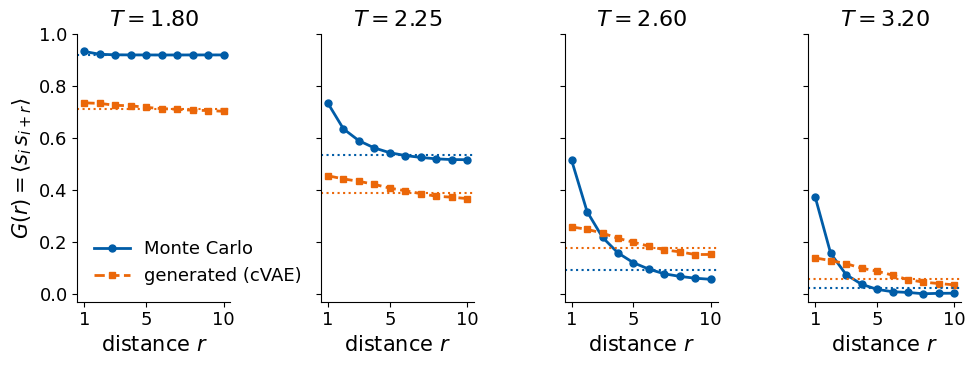

  T     r:     1      2      3      5     10   | <m^2> MC  gen | max_r |G_MC - G_gen|  max_r |G_gen - G_from_means|
1.80 mc     0.934  0.923  0.921  0.921  0.921   | 0.921  0.713 | 0.217   0.005
1.80 gen    0.736  0.734  0.727  0.719  0.703
1.80 mean   0.740  0.736  0.732  0.722  0.709
        connected G_c(r) = G(r) - <m^2> at r = 1, 2, 3:  MC  0.013  0.002  0.000   generated  0.023  0.021  0.014
2.25 mc     0.734  0.636  0.590  0.544  0.517   | 0.534  0.388 | 0.279   0.002
2.25 gen    0.455  0.443  0.434  0.408  0.367
2.25 mean   0.453  0.445  0.435  0.409  0.369
        connected G_c(r) = G(r) - <m^2> at r = 1, 2, 3:  MC  0.200  0.101  0.056   generated  0.067  0.055  0.046
2.60 mc     0.515  0.317  0.218  0.120  0.056   | 0.093  0.178 | 0.257   0.008
2.60 gen    0.258  0.249  0.234  0.199  0.152
2.60 mean   0.259  0.250  0.237  0.205  0.155
        connected G_c(r) = G(r) - <m^2> at r = 1, 2, 3:  MC  0.422  0.224  0.125   generated  0.080  0.071  0.056
3.20 mc     0.373  0.156  0.0

In [10]:
def corr(s, r_max=10):
    # G(r) = < (1/2N) sum_i s_i (s_{i + r x} + s_{i + r y}) >, r = 1..r_max; s: (configurations, L, L)
    return np.array([0.5 * (s * np.roll(s, -r, -1) + s * np.roll(s, -r, -2)).mean() for r in range(1, r_max + 1)])

T_corr = [1.8, 2.25, 2.6, 3.2]
rr = np.arange(1, 11)
G = {T: dict(mc=corr(cfg[iT(T)]), gen=corr(gen[iT(T)]), mean=corr(2 * prob[iT(T)] - 1),
             m2_mc=float((cfg[iT(T)].mean((-1, -2)) ** 2).mean()), m2_gen=float((gen[iT(T)].mean((-1, -2)) ** 2).mean()))
     for T in T_corr}

fig, axs = plt.subplots(1, 4, figsize=(10, 3.9), sharey=True)
for a, T in zip(axs, T_corr):
    a.plot(rr, G[T]["mc"], "o-", ms=5, lw=2, color=blue, label="Monte Carlo")
    a.plot(rr, G[T]["gen"], "s--", ms=5, lw=2, color=orange, label="generated (cVAE)")
    a.axhline(G[T]["m2_mc"], color=blue, ls=":", lw=1.5); a.axhline(G[T]["m2_gen"], color=orange, ls=":", lw=1.5)
    a.set_title(f"$T = {Ts[iT(T)]:.2f}$"); a.set_xlabel("distance $r$"); a.set_xticks([1, 5, 10]); a.set_ylim(-0.03, 1.0); clean(a)
axs[0].set_ylabel(r"$G(r)=\langle s_i\, s_{i+r} \rangle$")
axs[0].legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig(f"{OUT}/ising_cvae_correlation.png", dpi=200, bbox_inches="tight"); plt.show()

print("  T     r:     1      2      3      5     10   | <m^2> MC  gen | max_r |G_MC - G_gen|  max_r |G_gen - G_from_means|")
for T in T_corr:
    g = G[T]
    for lab in ("mc", "gen", "mean"):
        print(f"{Ts[iT(T)]:.2f} {lab:5s} " + " ".join(f"{g[lab][r - 1]:6.3f}" for r in (1, 2, 3, 5, 10)), end="")
        print(f"   | {g['m2_mc']:.3f}  {g['m2_gen']:.3f} | {np.abs(g['mc'] - g['gen']).max():.3f}   {np.abs(g['gen'] - g['mean']).max():.3f}" if lab == "mc" else "")
    nums[f"corr_maxdiff_T{T}"] = float(np.abs(g["mc"] - g["gen"]).max())
    nums[f"corr_r1_mc_T{T}"], nums[f"corr_r1_gen_T{T}"] = float(g["mc"][0]), float(g["gen"][0])
    Gc_mc, Gc_gen = g["mc"] - g["m2_mc"], g["gen"] - g["m2_gen"]
    print(f"        connected G_c(r) = G(r) - <m^2> at r = 1, 2, 3:  MC " + " ".join(f"{v:6.3f}" for v in Gc_mc[:3])
          + "   generated " + " ".join(f"{v:6.3f}" for v in Gc_gen[:3]))

The generated correlation functions are too flat. At short distances they are far too small: at temperature 3.2 the connected correlation of nearest neighbours, equation (18) at distance 1, is 0.352 for MC and 0.080 for the generated configurations, and at 2.6 it is 0.422 against 0.080. At large distances they are too large: at 3.2 and distance 10, $G$ is 0.003 for MC and 0.035 for the generated configurations, and at 2.6 and 3.2 the generated $\langle m^2\rangle_T$ (0.178 and 0.059) exceeds the MC value (0.093 and 0.022). The largest difference between the MC and the generated $G(r)$ over the ten distances is 0.217, 0.279, 0.257 and 0.234 at temperatures 1.8, 2.25, 2.6 and 3.2.

The correlation function computed from the decoder means agrees with that of the generated configurations to within 0.008 at all four temperatures, as equation (19) requires: every correlation between spins passes through $\mathbf z$. A probability map that varies smoothly over the lattice can place large domains, which produces the long-range part, but the short-range order of the Ising model, which neighbour is aligned with which, differs from configuration to configuration. Encoding it would need a different probability map for each microscopic arrangement, far more than 8 latent numbers carry (about 9 bits, from the KL term). The missing short-range correlation is the same defect that raised the energy.

## Phase classifier and critical temperature

Lab 011 found the critical temperature with a classifier that never sees the transition region, following Carrasquilla and Melko [[3]](#references). A related approach, in which networks are trained with labels split at a trial critical temperature and the true one is recognised by the accuracy of the training, is "learning by confusion" [[4]](#references). Configurations from temperatures below $T_{\min}$ are labelled ordered, those above $T_{\max}$ disordered, and the rest are not used for training:
$$
y=\begin{cases}0\ (\text{ordered}), & T<T_{\min}=1.8,\\ 1\ (\text{disordered}), & T>T_{\max}=2.8 .\end{cases} \tag{21}
$$
This selects 16 temperatures for the ordered and 14 for the disordered class, 6000 labelled configurations, of which 20% are kept aside for validation. The network outputs two numbers $o_0,o_1$, turned into probabilities by the softmax function,
$$
p_k(\mathbf s)=\frac{e^{o_k}}{e^{o_0}+e^{o_1}},\qquad k\in\{0,1\}, \tag{22}
$$
and is trained with the cross-entropy loss. Its confidence on a configuration is
$$
\mathrm{conf}(\mathbf s)=\max\left(p_0(\mathbf s),\,p_1(\mathbf s)\right). \tag{23}
$$
After training the classifier is applied at every temperature. Near $T_c$ the configurations look like neither class, the confidence drops towards $\frac12$, and the average $\langle p_1\rangle_T$ passes through $\frac12$. The estimate $\bar T_c$ is the temperature of this crossing,
$$
\left\langle p_1\right\rangle_{\bar T_c}=\tfrac12 , \tag{24}
$$
found by linear interpolation between the two neighbouring temperatures of the grid.

The network is that of Lab 011 and fits the $20\times20$ lattice without change: two convolutional layers with 32 kernels of size $3\times3$ and circular padding (the lattice is a torus), each followed by ReLU and $2\times2$ max-pooling (20 → 10 → 5 sites per side), then a dense layer of 64 ReLU units and 2 outputs; it is trained with Adam for 5 epochs.

Three experiments test the generated configurations from three sides:

- (a) the classifier trained on MC configurations and applied to MC configurations at all temperatures, the reference;
- (b) the same classifiers applied to the generated configurations, which shows whether a network that learned the phases from MC data sees the transition of the generated data at the same temperature;
- (c) a classifier trained on generated configurations (same temperature windows) and applied to MC configurations, which shows whether the generated data can teach a network the transition of the real system.

A single training run is itself a random experiment (Lab 011 found a spread of a few hundredths in $\bar T_c$), so each classifier is trained with three seeds.

In [11]:
class IsingCNN(nn.Module):                         # the network of Lab 011
    def __init__(self, L, channels=32, hidden=64, out=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, channels, 3, padding=1, padding_mode="circular"), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(channels, channels, 3, padding=1, padding_mode="circular"), nn.ReLU(), nn.MaxPool2d(2))
        side = L // 4                                                  # two 2x2 poolings
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(channels * side * side, hidden), nn.ReLU(), nn.Linear(hidden, out))
    def forward(self, x):
        return self.head(self.features(x))

T_MIN, T_MAX = 1.8, 2.8
torch.set_num_threads(8)                           # the convolutional networks use all 8 allowed cores
to_t = lambda a: torch.tensor(a, dtype=torch.float32).reshape(-1, 1, L, L)

def labelled_set(configs, rng, val_fraction=0.2):
    low, high = Ts < T_MIN, Ts > T_MAX
    X = np.concatenate([configs[low].reshape(-1, L, L), configs[high].reshape(-1, L, L)])
    y = np.concatenate([np.zeros(low.sum() * nS), np.ones(high.sum() * nS)])
    perm = rng.permutation(len(y)); X, y = X[perm], y[perm]; n_val = int(val_fraction * len(y))
    return to_t(X[n_val:]), torch.tensor(y[n_val:]).long(), to_t(X[:n_val]), torch.tensor(y[:n_val]).long()

def train_classifier(model, X, y, epochs=5, bs=64, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(y))
        for i in range(0, len(y), bs):
            j = perm[i:i + bs]; loss = F.cross_entropy(model(X[j]), y[j])
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

def predict_p1(model, configs):                # softmax probability of "disordered": (temperatures, configurations)
    X = to_t(configs)
    with torch.no_grad():
        p = torch.cat([torch.softmax(model(X[i:i + 2048]), 1)[:, 1] for i in range(0, len(X), 2048)])
    return p.numpy().reshape(configs.shape[:2])

def T_cross(p1):                                # temperature where <p_1>_T crosses 1/2 (linear interpolation)
    pm = p1.mean(1); i = int(np.argmax(pm >= 0.5))
    return float(Ts[i - 1] + (0.5 - pm[i - 1]) * (Ts[i] - Ts[i - 1]) / (pm[i] - pm[i - 1]))

print("labelled temperatures, ordered:   ", Ts[Ts < T_MIN])
print("labelled temperatures, disordered:", Ts[Ts > T_MAX])

labelled temperatures, ordered:    [1.   1.05 1.1  1.15 1.2  1.25 1.3  1.35 1.4  1.45 1.5  1.55 1.6  1.65
 1.7  1.75]
labelled temperatures, disordered: [2.85 2.9  2.95 3.   3.05 3.1  3.15 3.2  3.25 3.3  3.35 3.4  3.45 3.5 ]


In [12]:
seeds = (0, 1, 2)
clf = {"mc": [], "gen": []}; val_acc = {"mc": [], "gen": []}; val_sets = {}
t0 = time.time()
for src, data in (("mc", cfg), ("gen", gen)):
    for sd in seeds:
        torch.manual_seed(sd)
        Xa, ya, Xb, yb = labelled_set(data, np.random.default_rng(sd))
        m = train_classifier(IsingCNN(L), Xa, ya)
        with torch.no_grad(): acc = (m(Xb).argmax(1) == yb).float().mean().item()
        clf[src].append(m); val_acc[src].append(acc)
        if sd == 0: val_sets[src] = (Xb, yb)
    torch.save([m.state_dict() for m in clf[src]], f"{RES}/ising_phase_classifier_trained_on_{src}.pt")
t_clf = time.time() - t0
print(f"6 classifiers trained in {t_clf:.0f} s")
for src in clf: print(f"trained on {src:3s}: validation accuracy per seed", [round(a, 4) for a in val_acc[src]])

6 classifiers trained in 27 s
trained on mc : validation accuracy per seed [1.0, 1.0, 1.0]
trained on gen: validation accuracy per seed [0.95, 0.95, 0.9492]


The confusion matrices of the seed-0 classifiers on the held-out labelled MC configurations (rows: true phase, columns: predicted phase) show the errors on the training task itself. For the classifier trained on generated data this is already a transfer test, since it never saw MC data.

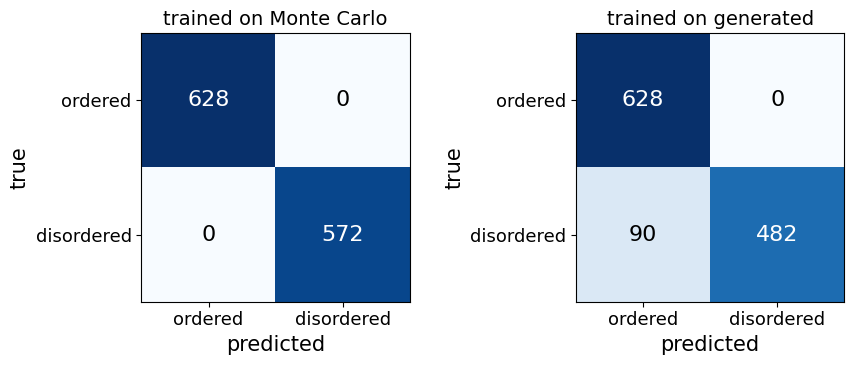

{'mc': [[628, 0], [0, 572]], 'gen': [[628, 0], [90, 482]]}


In [13]:
Xv, yv = val_sets["mc"]
fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
conf_mats = {}
for a, src in zip(axs, ("mc", "gen")):
    with torch.no_grad(): pred = clf[src][0](Xv).argmax(1)
    cm = np.array([[int(((yv == t) & (pred == p)).sum()) for p in (0, 1)] for t in (0, 1)]); conf_mats[src] = cm.tolist()
    a.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum(1).max())
    for t in (0, 1):
        for p in (0, 1): a.text(p, t, cm[t, p], ha="center", va="center", fontsize=16, color="white" if cm[t, p] > cm.max() / 2 else "black")
    a.set_xticks([0, 1], ["ordered", "disordered"]); a.set_yticks([0, 1], ["ordered", "disordered"])
    a.set_xlabel("predicted"); a.set_ylabel("true")
    a.set_title("trained on Monte Carlo" if src == "mc" else "trained on generated", fontsize=14)
plt.tight_layout(); plt.show()
np.savez(f"{RES}/ising_phase_classifier_confusion.npz", mc=np.array(conf_mats["mc"]), gen=np.array(conf_mats["gen"]))
print(conf_mats)

The curves are pooled over the three seeds; the crossing $\bar T_c$ is computed for every seed separately.

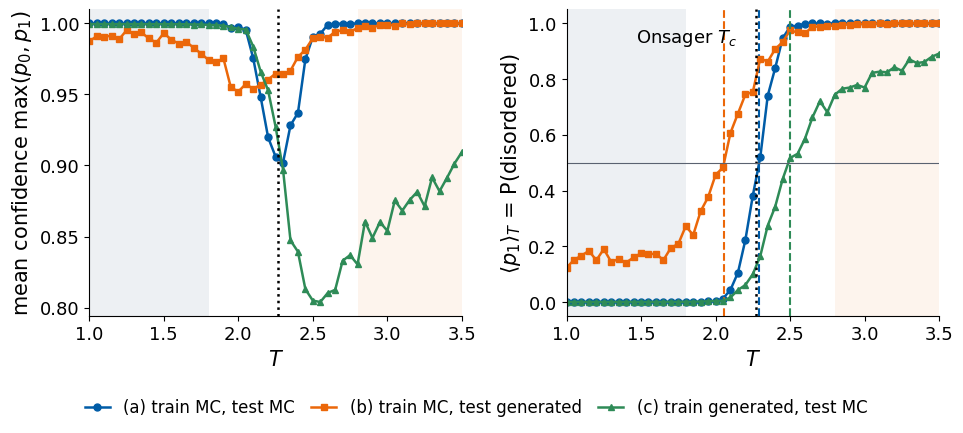

experiment                                 T_c per seed           mean +- std      minimum of mean confidence at T
(a) train MC, test MC                      2.280  2.291  2.304   2.292 +- 0.012    2.30
(b) train MC, test generated               2.047  2.053  2.069   2.056 +- 0.012    2.00
(c) train generated, test MC               2.566  2.476  2.460   2.501 +- 0.057    2.55
Onsager (infinite lattice)                 2.269


In [14]:
runs = {"a": ("mc", cfg), "b": ("mc", gen), "c": ("gen", cfg)}
labels = {"a": "(a) train MC, test MC", "b": "(b) train MC, test generated", "c": "(c) train generated, test MC"}
P1, Tc_est = {}, {}
for k, (src, data) in runs.items():
    P1[k] = [predict_p1(m, data) for m in clf[src]]
    Tc_est[k] = np.array([T_cross(p) for p in P1[k]])

colours = {"a": blue, "b": orange, "c": "#2E8B57"}; markers = {"a": "o", "b": "s", "c": "^"}
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))
for k in runs:
    p = np.concatenate(P1[k], 1)
    axs[0].plot(Ts, np.maximum(p, 1 - p).mean(1), markers[k] + "-", ms=5, lw=1.8, color=colours[k], label=labels[k])
    axs[1].plot(Ts, p.mean(1), markers[k] + "-", ms=5, lw=1.8, color=colours[k])
    axs[1].axvline(Tc_est[k].mean(), color=colours[k], ls="--", lw=1.5)
for a in axs:
    a.axvspan(Ts[0], T_MIN, color=navy, alpha=0.07, lw=0); a.axvspan(T_MAX, Ts[-1], color=orange, alpha=0.07, lw=0)
    a.axvline(TC, color="k", ls=":", lw=1.8); a.set_xlabel("$T$"); a.set_xlim(Ts[0], Ts[-1]); clean(a)
axs[1].axhline(0.5, color=gray, lw=0.8)
axs[1].text(TC - 0.12, 0.93, "Onsager $T_c$", fontsize=13, ha="right")
axs[0].set_ylabel(r"mean confidence $\max(p_0, p_1)$"); axs[1].set_ylabel(r"$\langle p_1 \rangle_T$ = P(disordered)")
fig.legend(*axs[0].get_legend_handles_labels(), frameon=False, loc="lower center", ncol=3, fontsize=12,
           handlelength=1.5, columnspacing=1.0, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.savefig(f"{OUT}/ising_cvae_confidence.png", dpi=200, bbox_inches="tight"); plt.show()

print(f"{'experiment':42s} T_c per seed           mean +- std      minimum of mean confidence at T")
for k in runs:
    p = np.concatenate(P1[k], 1); Tmin_conf = float(Ts[np.argmin(np.maximum(p, 1 - p).mean(1))])
    print(f"{labels[k]:42s} {'  '.join(f'{v:.3f}' for v in Tc_est[k])}   {Tc_est[k].mean():.3f} +- {Tc_est[k].std(ddof=1):.3f}    {Tmin_conf:.2f}")
    nums[f"Tc_{k}_mean"], nums[f"Tc_{k}_std"], nums[f"Tc_{k}_seeds"] = float(Tc_est[k].mean()), float(Tc_est[k].std(ddof=1)), Tc_est[k].tolist()
    nums[f"Tc_{k}_minconf"] = Tmin_conf
print(f"{'Onsager (infinite lattice)':42s} {TC:.3f}")

| experiment | $\bar T_c$ per seed | mean ± standard deviation | minimum of the mean confidence |
|---|---|---|---|
| (a) trained on MC, tested on MC | 2.280, 2.291, 2.304 | 2.292 ± 0.012 | 2.30 |
| (b) trained on MC, tested on generated | 2.047, 2.053, 2.069 | 2.056 ± 0.012 | 2.00 |
| (c) trained on generated, tested on MC | 2.566, 2.476, 2.460 | 2.501 ± 0.057 | 2.55 |
| Onsager, infinite lattice | | 2.269 | |

On MC data the classifier locates the transition at 2.292 ± 0.012 (mean and standard deviation over three seeds), 0.023 above Onsager's value. This is not an error of the method but a property of the finite lattice: on an $L\times L$ lattice the transition is smeared out, and a pseudo-critical temperature $T_c(L)$, defined by any feature of the transition region, approaches $T_c$ as
$$
T_c(L)-T_c\propto L^{-1/\nu}, \tag{25}
$$
with the correlation-length exponent $\nu$, which equals 1 for the 2D Ising model, and a prefactor that depends on the chosen feature. For $L$ equal to 20 shifts of a few hundredths are therefore expected; the maxima of $\chi'$ and $C'$ of the same MC data lie at 2.35 and 2.30.

(b) The classifier trained on MC data places the transition of the generated configurations at 2.056 ± 0.012, about 0.24 lower than for MC data. Generated configurations look disordered too early, consistent with their excess of isolated flipped spins and too-high energy, and even deep in the ordered phase the average probability of "disordered" stays between about 0.1 and 0.2 instead of 0, partly because of the minority of generated configurations with small $|m|$.

(c) The classifier trained on generated configurations reaches 95% validation accuracy on its own data, and on the labelled MC configurations it calls 90 of the 572 disordered ones ordered (confusion matrix). Applied to MC data at all temperatures, it places the transition at 2.501 ± 0.057, 0.21 above the MC reference, with three times the seed-to-seed spread, and even at temperature 3.5 the average probability of "disordered" for MC configurations stays below 0.9. Having learned "disordered" from the speckled generated configurations, the network finds the MC configurations, with their compact clusters, too ordered. Both transfer experiments shift the transition by about 0.2 in opposite directions, roughly ten times the finite-size shift of the reference estimate.

## Temperature regression

The phase classifier only distinguishes two phases. A stricter test asks for the temperature itself. A CNN with the same architecture but a single output $\hat c$ is trained to predict the condition of equation (8) from a configuration, with the mean squared error as loss, and the prediction is converted back to a temperature,
$$
\hat T=2.25+0.75\,\hat c . \tag{26}
$$
To have unseen test data, the 200 configurations at each temperature are split at random into 150 for training and 50 for testing, for the MC and the generated data alike. Applied to generated configurations at requested temperature $T$, the regressor trained on MC data tells at which temperature these configurations look as if they had been sampled. A second regressor, trained on generated data, completes a $2\times2$ table of the mean absolute error over a test set,
$$
\mathrm{MAE}=\left\langle\,\left|\hat T-T\right|\,\right\rangle . \tag{27}
$$
The cVAE was trained on all 200 MC configurations per temperature, so the MC test configurations are new for the regressors but not for the generator.

In [15]:
split_rng = np.random.default_rng(3)
perm = np.array([split_rng.permutation(nS) for _ in range(nT)])                  # random split, per temperature
tr_idx, te_idx = perm[:, :150], perm[:, 150:]
take = lambda data, idx: np.take_along_axis(data, idx[:, :, None, None], 1)   # (temperatures, k, L, L)
sets = {"mc": (take(cfg, tr_idx), take(cfg, te_idx)), "gen": (take(gen, tr_idx), take(gen, te_idx))}

def train_regressor(data, epochs=12, bs=64, lr=1e-3, sd=0):
    torch.manual_seed(sd)
    X = to_t(data); y = torch.tensor(np.repeat(Tn(Ts), data.shape[1]))[:, None]
    model = IsingCNN(L, out=1); opt = torch.optim.Adam(model.parameters(), lr)
    for ep in range(epochs):
        model.train(); p = torch.randperm(len(y))
        for i in range(0, len(y), bs):
            j = p[i:i + bs]; loss = F.mse_loss(model(X[j]), y[j])
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

def predict_T(model, data):
    with torch.no_grad(): c = model(to_t(data)).numpy().reshape(data.shape[:2])
    return 2.25 + 0.75 * c

t0 = time.time()
reg = {src: train_regressor(sets[src][0]) for src in ("mc", "gen")}
t_reg = time.time() - t0
for src in reg: torch.save(reg[src].state_dict(), f"{RES}/ising_T_regressor_trained_on_{src}.pt")
pred = {(a, b): predict_T(reg[a], sets[b][1]) for a in reg for b in reg}           # (trained on, tested on)
mae = {k: float(np.abs(v - Ts[:, None]).mean()) for k, v in pred.items()}
print(f"2 regressors trained in {t_reg:.0f} s")
print("mean absolute error of T (test sets, 50 configurations per temperature)")
print("                      tested on MC   tested on generated")
for a in reg: print(f"trained on {a:4s}        {mae[(a, 'mc')]:.3f}          {mae[(a, 'gen')]:.3f}")
for k, v in mae.items(): nums[f"T_mae_train_{k[0]}_test_{k[1]}"] = v

2 regressors trained in 76 s
mean absolute error of T (test sets, 50 configurations per temperature)
                      tested on MC   tested on generated
trained on mc          0.134          0.533
trained on gen         0.332          0.302


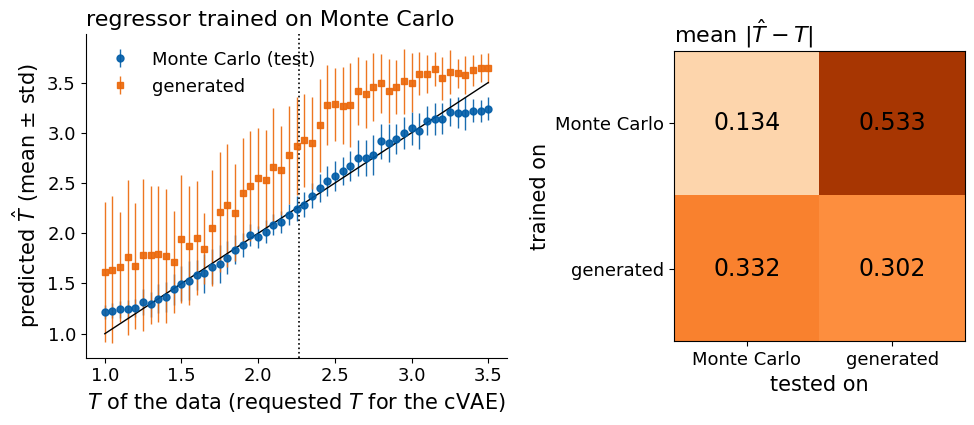

bias of the MC-trained regressor on generated configurations, <T_hat> - T, at selected T:
  T = 1.20: generated +0.474   MC test +0.056
  T = 1.50: generated +0.441   MC test -0.000
  T = 1.80: generated +0.477   MC test -0.043
  T = 2.00: generated +0.549   MC test -0.037
  T = 2.25: generated +0.622   MC test -0.005
  T = 2.50: generated +0.784   MC test +0.071
  T = 2.80: generated +0.695   MC test +0.115
  T = 3.00: generated +0.498   MC test +0.045
  T = 3.40: generated +0.223   MC test -0.178


In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), gridspec_kw=dict(width_ratios=[1.45, 1]))
a = axs[0]
for b, col, mk, lab in (("mc", blue, "o", "Monte Carlo (test)"), ("gen", orange, "s", "generated")):
    p = pred[("mc", b)]
    a.errorbar(Ts, p.mean(1), yerr=p.std(1), fmt=mk, ms=5, color=col, ecolor=col, elinewidth=1, capsize=0, alpha=0.9, label=lab)
a.plot([1, 3.5], [1, 3.5], color="k", lw=1)
a.axvline(TC, color="k", ls=":", lw=1.2)
a.set_xlabel("$T$ of the data (requested $T$ for the cVAE)"); a.set_ylabel(r"predicted $\hat T$ (mean $\pm$ std)")
a.set_title("regressor trained on Monte Carlo", loc="left"); a.legend(frameon=False, loc="upper left"); clean(a)
a = axs[1]
M = np.array([[mae[("mc", "mc")], mae[("mc", "gen")]], [mae[("gen", "mc")], mae[("gen", "gen")]]])
a.imshow(M, cmap="Oranges", vmin=0, vmax=M.max() * 1.15)
for i in range(2):
    for j in range(2): a.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=17, color="black")
a.set_xticks([0, 1], ["Monte Carlo", "generated"]); a.set_yticks([0, 1], ["Monte Carlo", "generated"])
a.set_xlabel("tested on"); a.set_ylabel("trained on"); a.set_title(r"mean $|\hat T - T|$", loc="left")
plt.tight_layout(); plt.savefig(f"{OUT}/ising_cvae_T_regression.png", dpi=200, bbox_inches="tight"); plt.show()

bias = pred[("mc", "gen")].mean(1) - Ts
print("bias of the MC-trained regressor on generated configurations, <T_hat> - T, at selected T:")
for T in (1.2, 1.5, 1.8, 2.0, 2.25, 2.5, 2.8, 3.0, 3.4):
    i = iT(T); print(f"  T = {Ts[i]:.2f}: generated {bias[i]:+.3f}   MC test {pred[('mc', 'mc')][i].mean() - Ts[i]:+.3f}")
    nums[f"T_bias_gen_T{Ts[i]:.2f}"] = float(bias[i])

On unseen MC configurations the regressor trained on MC predicts the temperature with a mean absolute error of 0.134. The error is largest at the ends of the range, where it pulls its predictions towards the middle (+0.056 at temperature 1.20, −0.178 at 3.40): at low temperature the configurations are almost identical, and at high temperature they change slowly with $T$. On generated configurations the same regressor gives 0.533: it reads them as systematically hotter than requested, by +0.44 at temperature 1.50, +0.62 at 2.25, +0.78 at 2.50 and +0.22 at 3.40, with a larger scatter. This is the temperature analogue of experiment (b), and consistent with the too-high energy.

The regressor trained on generated data reaches 0.302 on generated test configurations and 0.332 on MC. Its error on its own data is more than twice that of the MC regressor on MC data, since the generated configurations carry less information about the temperature, and transferring it to MC costs little. The opposite transfer, from MC to generated, costs most (0.533). Each regressor was trained once, so differences of a few hundredths in this table are within the variation from training to training.

In [17]:
nums.update(t_vae_s=t_vae, t_classifiers_s=t_clf, t_regressors_s=t_reg, total_runtime_s=time.time() - t_start,
            vae_loss_final=float(hist[-1, 0]), vae_rec_final=float(hist[-1, 1]), vae_kl_final=float(hist[-1, 2]),
            classifier_val_acc=val_acc, classifier_confusion=conf_mats, Tc_onsager=float(TC))
json.dump(nums, open(f"{RES}/numbers_ising_cvae.json", "w"), indent=1)
print(f"total run time {nums['total_runtime_s'] / 60:.1f} min; numbers written to {RES}/numbers_ising_cvae.json")

total run time 2.5 min; numbers written to results/numbers_ising_cvae.json


## Conclusion

The conditional VAE learns the coarse temperature dependence of the Ising model: the magnetisation drops around $T_c$, the energy rises with temperature, and the generated configurations change from ordered to disordered as the condition is varied. Every finer test exposes the same defect. The energy per spin is too high at every temperature (by up to 0.634), the fluctuations in the ordered phase are wrong by orders of magnitude because 8.5% of the generated low-temperature configurations have small magnetisation, and the correlation function is too small at short distances and too large at long ones. Networks confirm this from the outside: a classifier trained on MC data places the transition of the generated data at 2.056 instead of 2.292, a classifier trained on generated data places that of MC data at 2.501, and a regressor reads the generated configurations as hotter than requested by up to 0.78. The cause lies in the model itself: given $\mathbf z$ the decoder draws spins independently, so all correlations must pass through a latent vector of 8 numbers, and the short-range order of the Ising model does not fit through it. Generative models that keep the dependence between spins, such as autoregressive models, which draw one spin at a time conditioned on the previous ones, or diffusion models, address exactly this defect.

## Exercises

1. Retrain the cVAE with 32 latent variables. Does the connected nearest-neighbour correlation at temperature 2.6 move towards the MC value 0.422, and does the energy gap shrink?
2. Generate configurations at temperature 2.27, between two training temperatures, and read their temperature with the regressor trained on MC data.
3. The Lecture 4 data folder also contains $10\times10$ and $40\times40$ lattices. Locate the maxima of $\chi'$ and $C'$ of the MC data for the three lattice sizes and compare their shifts from $T_c$ with equation (25).

<a id="references"></a>
## References

1. L. Onsager, *Crystal Statistics. I. A Two-Dimensional Model with an Order-Disorder Transition*, Phys. Rev. **65**, 117 (1944), [doi:10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117)
2. N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller, E. Teller, *Equation of State Calculations by Fast Computing Machines*, J. Chem. Phys. **21**, 1087 (1953), [doi:10.1063/1.1699114](https://doi.org/10.1063/1.1699114)
3. J. Carrasquilla, R. G. Melko, *Machine learning phases of matter*, Nat. Phys. **13**, 431 (2017), [doi:10.1038/nphys4035](https://doi.org/10.1038/nphys4035), [arXiv:1605.01735](https://arxiv.org/abs/1605.01735)
4. E. P. L. van Nieuwenburg, Y.-H. Liu, S. D. Huber, *Learning phase transitions by confusion*, Nat. Phys. **13**, 435 (2017), [doi:10.1038/nphys4037](https://doi.org/10.1038/nphys4037)
5. D. P. Kingma, M. Welling, *Auto-Encoding Variational Bayes* (2013), [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)